In [5]:
!pip install ultralytics

In [1]:
import os, random, shutil

random.seed(42)
image_dir = "images"
label_dir = "labels"
out_dir = "dataset"

images = [f for f in os.listdir(image_dir) if f.endswith(('.jpg', '.jpeg', '.png'))]
random.shuffle(images)

split_idx = int(len(images) * 0.85)
splits = {"train": images[:split_idx], "val": images[split_idx:]}

for split, files in splits.items():
    os.makedirs(f"{out_dir}/images/{split}", exist_ok=True)
    os.makedirs(f"{out_dir}/labels/{split}", exist_ok=True)
    for f in files:
        name = os.path.splitext(f)[0]
        shutil.copy(f"{image_dir}/{f}", f"{out_dir}/images/{split}/{f}")
        label_file = f"{label_dir}/{name}.txt"
        if os.path.exists(label_file):
            shutil.copy(label_file, f"{out_dir}/labels/{split}/{name}.txt")

In [2]:
import os
with open("classes.txt") as f:
    class_names = [line.strip() for line in f if line.strip()]

yaml_content = f"""
path: {os.path.abspath('dataset')}
train: images/train
val: images/val

nc: {len(class_names)}
names: {class_names}
"""

with open("dataset/data.yaml", "w") as f:
    f.write(yaml_content)

print(yaml_content)


path: C:\Users\Javie\Downloads\Notebook 1\dataset
train: images/train
val: images/val

nc: 39
names: ['Bolsa', 'Caja', 'Campanario Chirimoya Colada 12Â°', 'Campanario Cola de Mono 12Â°', 'Campanario Mango Colada 12Â°', 'Campanario PiÃ±a Colada 12Â°', 'Campanario SelecciÃ³n Creme 14Â°', 'Campanario Sour 14Â°', 'Campanario Sour Mango 12Â°', 'Campanario Sour MaracuyÃ¡ 12Â°', 'Campanario Sour Menta Jengibre 12Â°', 'HorcÃ³n Quemado Pisco Sour 14Â°', 'ICE Berg Extreme Blue', 'Kantal Gin & Berries 7Â°', 'Kantal Gin & Summer 7Â°', 'Kantal Gin & Tonic 7Â°', 'Kantal Tropical Gin 7Â°', 'Mistral ICE Blend 7Â° Botellin', 'Mistral ICE Blend Lata', 'Mistral ICE Dry 7Â°', 'Mistral ICE Energy Botellin', 'Mistral ICE Energy Lata', 'Mistral ICE Low 2,5Â°', 'Mistral ICE Maqui Granada 7Â°', 'Precio', 'Ramazzotti Crema', 'Ruta Cocktail Mango Sour 12Â°', 'Ruta Cocktail Pisco Sour 14Â°', 'Sabor Andino Calafate 12Â°', 'Sabor Andino Mango 12Â°', 'Sabor Andino Sour 12Â°', 'Sierra Morena ICE Mojito Berries 7Â°',

In [6]:
from ultralytics import YOLO

# 'n' = nano, the smallest/fastest YOLO variant — good starting point
model = YOLO("yolov8n.pt")  # loads pretrained nano weights (transfer learning)

results = model.train(
    data="dataset/data.yaml",
    epochs=2000,
    imgsz=640,
    batch=1,
    degrees=15,        # rotation
    flipud=0.5,         
    fliplr=0.5,
    mosaic=1.0,         # combines 4 images into 1 — very helpful for small datasets
    mixup=0.2,
    hsv_h=0.02, hsv_s=0.7, hsv_v=0.4,  # color jitter
    patience=0,       # early stopping if val doesn't improve
    device="cpu"           # GPU index; use "cpu" if no GPU
)

New https://pypi.org/project/ultralytics/8.4.191 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.189  Python-3.14.9 torch-2.14.1+cpu CPU (Intel Core i5-8265U 1.60GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=15, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2000, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.02, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.2, mode=train, model=yolov8n.pt, momentum=0.937, m

In [17]:
#Detectar visualmente las botellas
from ultralytics import YOLO

# Cargar el modelo con los pesos del entrenamiento
model = YOLO("runs/detect/train-2/weights/best.pt")

# Ruta a la imagen en Descargas
ruta_imagen = r"C:\Users\Javie\Downloads\rex_20905214_23414_8dc71072c9ed_1778079329495.jpg"

# Predecir usando exactamente los parámetros del Método 2
results = model(ruta_imagen, imgsz=640, conf=0.18, iou=0.45)

results[0].show()
print(results[0].boxes)



image 1/1 C:\Users\Javie\Downloads\rex_20905214_23414_8dc71072c9ed_1778079329495.jpg: 640x256 2 Campanario Chirimoya Colada 12°s, 2 Campanario Cola de Mono 12°s, 1 Campanario Mango Colada 12°, 2 Campanario Piña Colada 12°s, 2 Campanario Sour 14°s, 1 Campanario Sour Mango 12°, 2 Campanario Sour Menta Jengibre 12°s, 1 Horcón Quemado Pisco Sour 14°, 3 ICE Berg Extreme Blues, 1 Kantal Gin & Berries 7°, 2 Kantal Gin & Tonic 7°s, 1 Kantal Tropical Gin 7°, 1 Mistral ICE Blend 7° Botellin, 2 Mistral ICE Blend Latas, 1 Mistral ICE Dry 7°, 1 Mistral ICE Energy Botellin, 2 Mistral ICE Energy Latas, 1 Mistral ICE Low 2,5°, 1 Mistral ICE Maqui Granada 7°, 1 Ruta Cocktail Mango Sour 12°, 1 Sabor Andino Calafate 12°, 1 Sabor Andino Mango 12°, 1 Sabor Andino Sour 12°, 1 Sierra Morena ICE Mojito Berries 7°, 5 Sierra Morena ICE Mojito Botellins, 2 Sierra Morena ICE Mojito Latas, 1 Sierra Morena ICE Mojito Maracuya 7°, 59.5ms
Speed: 1.8ms preprocess, 59.5ms inference, 1.9ms postprocess per image at shap

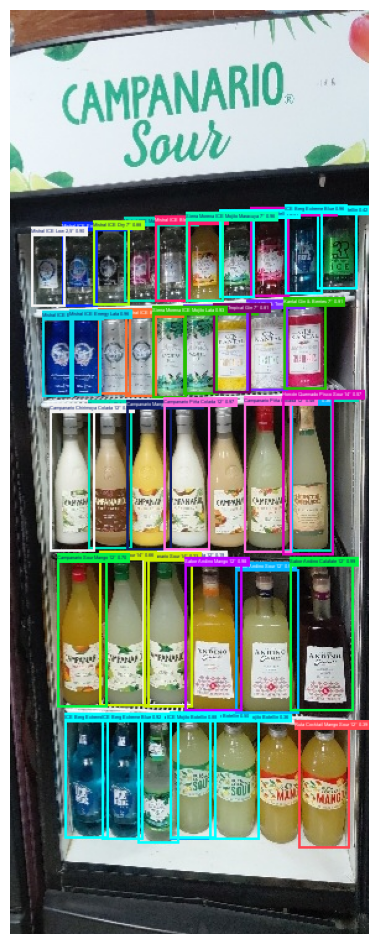

In [18]:
#Detectar visualmente las botellas en el Notebook
import matplotlib.pyplot as plt
import cv2

# Generar la imagen con las cajas ajustadas
img_procesada = results[0].plot(line_width=2, font_size=4) 

# Muestra la imagen en el notebook
plt.figure(figsize=(12, 12))
plt.imshow(cv2.cvtColor(img_procesada, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()


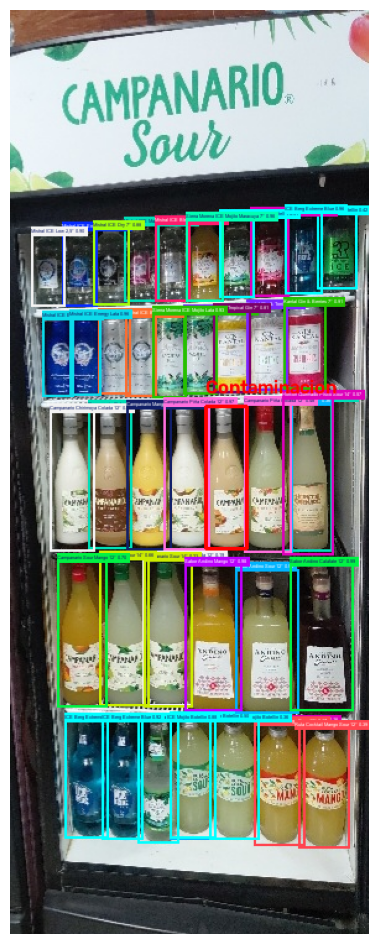

In [19]:
# Todo lo que no es calsificado sea marcado como contaminación
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Función para calcular IoU
def calcular_iou(caja1, caja2):
    x_izq = max(caja1[0], caja2[0])
    y_sup = max(caja1[1], caja2[1])
    x_der = min(caja1[2], caja2[2])
    y_inf = min(caja1[3], caja2[3])

    if x_der < x_izq or y_inf < y_sup:
        return 0.0

    area_interseccion = (x_der - x_izq) * (y_inf - y_sup)
    area_caja1 = (caja1[2] - caja1[0]) * (caja1[3] - caja1[1])
    area_caja2 = (caja2[2] - caja2[0]) * (caja2[3] - caja2[1])
    return area_interseccion / float(area_caja1 + area_caja2 - area_interseccion)


modelo_generico = YOLO("yolov8n.pt") 
modelo_custom = YOLO("runs/detect/train-2/weights/best.pt")

ruta_img = r"C:\Users\Javie\Downloads\rex_20905214_23414_8dc71072c9ed_1778079329495.jpg"
img = cv2.imread(ruta_img)

# A) Predecir genérico (Botellas)
res_gen = modelo_generico(img, verbose=False, conf=0.25)
botellas_genericas = [caja.xyxy[0].cpu().numpy() for caja in res_gen[0].boxes if int(caja.cls[0]) == 39]

# B) Predecir custom a confianza BAJA (0.15)
res_cus = modelo_custom(img, verbose=False, imgsz=640, conf=0.15, iou=0.45)

# C) FILTRO: Eliminamos el Ramazzotti falso de los resultados antes de dibujar
indices_validos = []
for i, caja in enumerate(res_cus[0].boxes):
    nombre = res_cus[0].names[int(caja.cls[0])]
    conf = float(caja.conf[0])
    
    # Mantén tu regla para el Ramazzotti fantasma
    if "Ramazzotti" in nombre and conf < 0.18:
        continue
    indices_validos.append(i)

# Actualizamos los resultados solo con las detecciones válidas
res_cus[0].boxes = res_cus[0].boxes[indices_validos]
productos_reconocidos = [caja.xyxy[0].cpu().numpy() for caja in res_cus[0].boxes]

# D) DIBUJAR NATIVAMENTE CON YOLO
img_dibujada = res_cus[0].plot(line_width=2, font_size=4).copy()

# E) Dibujar Contaminación en Rojo
for bot_gen in botellas_genericas:
    es_contaminacion = True
    for prod_cus in productos_reconocidos:
        if calcular_iou(bot_gen, prod_cus) > 0.30:
            es_contaminacion = False
            break
    
    if es_contaminacion:
        x1, y1, x2, y2 = map(int, bot_gen)
        cv2.rectangle(img_dibujada, (x1, y1), (x2, y2), (0, 0, 255), 2)
        cv2.putText(img_dibujada, "Contaminacion", (x1, y1 - 10), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)

# Mostrar la imagen fusionada en el notebook
plt.figure(figsize=(12, 12))
plt.imshow(cv2.cvtColor(img_dibujada, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()


--- INVENTARIO DETECTADO ---
- Sabor Andino Calafate 12°: 1
- Sabor Andino Mango 12°: 1
- Campanario Piña Colada 12°: 2
- Sierra Morena ICE Mojito Maracuya 7°: 1
- ICE Berg Extreme Blue: 3
- Mistral ICE Energy Lata: 2
- Sierra Morena ICE Mojito Lata: 2
- Sabor Andino Sour 12°: 1
- Kantal Gin & Berries 7°: 1
- Sierra Morena ICE Mojito Botellin: 5
- Mistral ICE Low 2,5°: 1
- Sierra Morena ICE Mojito Berries 7°: 2
- Campanario Mango Colada 12°: 1
- Mistral ICE Dry 7°: 1
- Campanario Chirimoya Colada 12°: 2
- Kantal Tropical Gin 7°: 1
- Kantal Gin & Tonic 7°: 2
- Mistral ICE Energy Botellin: 1
- Mistral ICE Blend 7° Botellin: 1
- Campanario Sour Mango 12°: 1
- Mistral ICE Blend Lata: 2
- Campanario Sour 14°: 2
- Horcón Quemado Pisco Sour 14°: 1
- Mistral ICE Maqui Granada 7°: 1
- Ruta Cocktail Mango Sour 12°: 2
- Campanario Sour Menta Jengibre 12°: 2
- Campanario Cola de Mono 12°: 2
- Contaminación: 1

--- EVALUACIÓN DE TRADE MARKETING ---
Puntaje base inicial        : 2.50 pts
Categorías

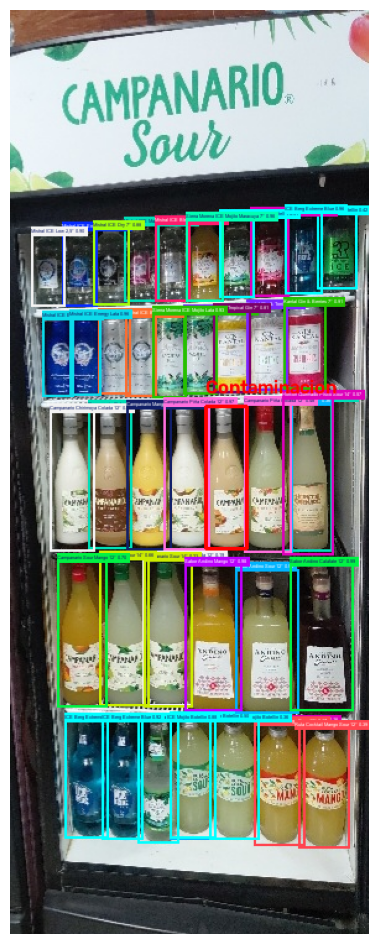

In [20]:
# Implementacion del modelo econometrico para el calculo de la nota
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Función para calcular IoU
def calcular_iou(caja1, caja2):
    x_izq = max(caja1[0], caja2[0])
    y_sup = max(caja1[1], caja2[1])
    x_der = min(caja1[2], caja2[2])
    y_inf = min(caja1[3], caja2[3])

    if x_der < x_izq or y_inf < y_sup:
        return 0.0

    area_interseccion = (x_der - x_izq) * (y_inf - y_sup)
    area_caja1 = (caja1[2] - caja1[0]) * (caja1[3] - caja1[1])
    area_caja2 = (caja2[2] - caja2[0]) * (caja2[3] - caja2[1])
    return area_interseccion / float(area_caja1 + area_caja2 - area_interseccion)


modelo_generico = YOLO("yolov8n.pt") 
modelo_custom = YOLO("runs/detect/train-2/weights/best.pt")

ruta_img = r"C:\Users\Javie\Downloads\rex_20905214_23414_8dc71072c9ed_1778079329495.jpg"
img = cv2.imread(ruta_img)

# A) Predecir genérico (Botellas)
res_gen = modelo_generico(img, verbose=False, conf=0.25)
botellas_genericas = [caja.xyxy[0].cpu().numpy() for caja in res_gen[0].boxes if int(caja.cls[0]) == 39]

# B) Predecir custom a confianza BAJA (0.15)
res_cus = modelo_custom(img, verbose=False, imgsz=640, conf=0.15, iou=0.45)

# C) Variables para el inventario y modelo econométrico
conteo_productos = {}
total_contaminacion = 0
indices_validos = []

# Filtrar detecciones y contar inventario
for i, caja in enumerate(res_cus[0].boxes):
    nombre = res_cus[0].names[int(caja.cls[0])]
    conf = float(caja.conf[0])
    
    # Filtro estricto para falso positivo
    if "Ramazzotti" in nombre and conf < 0.18:
        continue
        
    indices_validos.append(i)
    
    # Sumar al inventario
    if nombre not in conteo_productos:
        conteo_productos[nombre] = 0
    conteo_productos[nombre] += 1

# Actualizar cajas solo con las válidas para dibujar
res_cus[0].boxes = res_cus[0].boxes[indices_validos]
productos_reconocidos = [caja.xyxy[0].cpu().numpy() for caja in res_cus[0].boxes]

# D) Dibujar Nativamente con YOLO
img_dibujada = res_cus[0].plot(line_width=2, font_size=4).copy()

# E) Procesar y dibujar Contaminación
for bot_gen in botellas_genericas:
    es_contaminacion = True
    for prod_cus in productos_reconocidos:
        if calcular_iou(bot_gen, prod_cus) > 0.30:
            es_contaminacion = False
            break
    
    if es_contaminacion:
        total_contaminacion += 1
        x1, y1, x2, y2 = map(int, bot_gen)
        cv2.rectangle(img_dibujada, (x1, y1), (x2, y2), (0, 0, 255), 2)
        cv2.putText(img_dibujada, "Contaminacion", (x1, y1 - 10), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)

# F) IMPRIMIR RESULTADOS ANTES DE MOSTRAR LA IMAGEN
print("\n--- INVENTARIO DETECTADO ---")
for prod, cant in conteo_productos.items():
    print(f"- {prod}: {cant}")
print(f"- Contaminación: {total_contaminacion}")

# Cálculo de puntaje (Modelo de Presencia)
total_categorias_posibles = 39
categorias_presentes = len(conteo_productos)

# El modelo inicia con 2.5 puntos base y suma las categorías detectadas
puntaje_categorias = categorias_presentes * (10.0 / total_categorias_posibles)
puntaje_base = 2.5 + puntaje_categorias
penalizacion = total_contaminacion * 1.5

puntaje_final = puntaje_base - penalizacion
puntaje_final = max(0.0, min(10.0, puntaje_final)) # Acotar resultado entre 0 y 10

print("\n--- EVALUACIÓN DE TRADE MARKETING ---")
print(f"Puntaje base inicial        : 2.50 pts")
print(f"Categorías únicas presentes : {categorias_presentes}/{total_categorias_posibles} (+{puntaje_categorias:.2f} pts)")
print(f"Instancias de contaminación : {total_contaminacion} (-{penalizacion:.2f} pts)")
print(f"PUNTAJE FINAL DEL COOLER    : {puntaje_final:.2f} / 10.00")

# G) Mostrar imagen al final
plt.figure(figsize=(12, 12))
plt.imshow(cv2.cvtColor(img_dibujada, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

In [21]:
# Primera prueba con mini dataset
import os
import cv2
from ultralytics import YOLO

def calcular_iou(caja1, caja2):
    x_izq = max(caja1[0], caja2[0])
    y_sup = max(caja1[1], caja2[1])
    x_der = min(caja1[2], caja2[2])
    y_inf = min(caja1[3], caja2[3])

    if x_der < x_izq or y_inf < y_sup:
        return 0.0

    area_interseccion = (x_der - x_izq) * (y_inf - y_sup)
    area_caja1 = (caja1[2] - caja1[0]) * (caja1[3] - caja1[1])
    area_caja2 = (caja2[2] - caja2[0]) * (caja2[3] - caja2[1])
    return area_interseccion / float(area_caja1 + area_caja2 - area_interseccion)


modelo_generico = YOLO("yolov8n.pt") 
modelo_custom = YOLO("runs/detect/train-2/weights/best.pt")

# Rutas para el procesamiento masivo
ruta_carpeta_test = r"C:\Users\Javie\Downloads\Fotos Test" 
carpeta_salida = "runs/detect/evaluacion_trade_9"
os.makedirs(carpeta_salida, exist_ok=True)

imagenes = [img for img in os.listdir(ruta_carpeta_test) if img.lower().endswith(('.png', '.jpg', '.jpeg'))]
print(f"\nIniciando evaluación de {len(imagenes)} coolers...\n")
print("="*50)

for nombre_img in imagenes:
    ruta_img = os.path.join(ruta_carpeta_test, nombre_img)
    img = cv2.imread(ruta_img)
    
    # Predecir genérico (Botellas)
    res_gen = modelo_generico(img, verbose=False, conf=0.25)
    botellas_genericas = [caja.xyxy[0].cpu().numpy() for caja in res_gen[0].boxes if int(caja.cls[0]) == 39]
    
    # Predecir custom manteniendo sensibilidad global
    res_cus = modelo_custom(img, verbose=False, imgsz=640, conf=0.15, iou=0.45)
    
    conteo_productos_validos = {}
    instancias_caja_bolsa = 0
    total_contaminacion = 0
    indices_validos = []
    
    # Filtros por condición IF
    for i, caja in enumerate(res_cus[0].boxes):
        nombre = res_cus[0].names[int(caja.cls[0])]
        conf = float(caja.conf[0])
        
        # Regla 1: Falso positivo Ramazzotti
        if "Ramazzotti" in nombre and conf < 0.18:
            continue
            
        indices_validos.append(i)
        
        # Clasificar si es un objeto de penalización (caja/bolsa) o una categoría válida
        if "caja" in nombre.lower() or "bolsa" in nombre.lower():
            instancias_caja_bolsa += 1
        else:
            if nombre not in conteo_productos_validos:
                conteo_productos_validos[nombre] = 0
            conteo_productos_validos[nombre] += 1
        
    res_cus[0].boxes = res_cus[0].boxes[indices_validos]
    productos_reconocidos = [caja.xyxy[0].cpu().numpy() for caja in res_cus[0].boxes]
    
    img_dibujada = res_cus[0].plot(line_width=2, font_size=4).copy()
    
    # Procesar Contaminación
    for bot_gen in botellas_genericas:
        es_contaminacion = True
        for prod_cus in productos_reconocidos:
            if calcular_iou(bot_gen, prod_cus) > 0.30:
                es_contaminacion = False
                break
        
        if es_contaminacion:
            total_contaminacion += 1
            x1, y1, x2, y2 = map(int, bot_gen)
            cv2.rectangle(img_dibujada, (x1, y1), (x2, y2), (0, 0, 255), 2)
            cv2.putText(img_dibujada, "Contaminacion", (x1, y1 - 10), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)
    
    # Guardar imagen
    ruta_guardado = os.path.join(carpeta_salida, nombre_img)
    cv2.imwrite(ruta_guardado, img_dibujada)
    
    # Cálculos econométricos (Ajustado a 30 categorías y nuevas penalizaciones)
    categorias_presentes = len(conteo_productos_validos)
    
    # Se limita matemáticamente a 30 para que el puntaje base no supere los 10.0
    categorias_para_puntaje = min(categorias_presentes, 30)
    puntaje_categorias = categorias_para_puntaje * (7.5 / 30.0) 
    puntaje_base = 2.5 + puntaje_categorias
    
    # Penalizaciones separadas
    penalizacion_contaminacion = total_contaminacion * 1.5
    penalizacion_caja_bolsa = instancias_caja_bolsa * 0.25 # <-- Ajusta este valor según la severidad del castigo
    penalizacion_total = penalizacion_contaminacion + penalizacion_caja_bolsa
    
    puntaje_final = max(0.0, min(10.0, puntaje_base - penalizacion_total))
    
    # Imprimir consola
    print(f"ARCHIVO: {nombre_img}")
    print(f"- Categorías válidas (suman): {categorias_presentes}/30+")
    print(f"- Cajas/Bolsas detectadas (restan): {instancias_caja_bolsa}")
    print(f"- Contaminación: {total_contaminacion} instancias")
    print(f"- PUNTAJE FINAL: {puntaje_final:.2f} / 10.00")
    print("-" * 30)

print(f"\nEvaluación masiva completada. Revisa la carpeta: {carpeta_salida}")


Iniciando evaluación de 9 coolers...

ARCHIVO: rex_20905181_23415_42b8c28feb78_1778012324846.jpg
- Categorías válidas (suman): 20/30+
- Cajas/Bolsas detectadas (restan): 4
- Contaminación: 6 instancias
- PUNTAJE FINAL: 0.00 / 10.00
------------------------------
ARCHIVO: rex_20905181_23415_7aab7f44b6e2_1777996981134.jpg
- Categorías válidas (suman): 23/30+
- Cajas/Bolsas detectadas (restan): 0
- Contaminación: 2 instancias
- PUNTAJE FINAL: 5.25 / 10.00
------------------------------
ARCHIVO: rex_20905183_23414_0a4fcdcf9c8d_1778002843614.jpg
- Categorías válidas (suman): 11/30+
- Cajas/Bolsas detectadas (restan): 3
- Contaminación: 0 instancias
- PUNTAJE FINAL: 4.50 / 10.00
------------------------------
ARCHIVO: rex_20905186_23414_0fbf7414e6f1_1778004299588.jpg
- Categorías válidas (suman): 27/30+
- Cajas/Bolsas detectadas (restan): 0
- Contaminación: 1 instancias
- PUNTAJE FINAL: 7.75 / 10.00
------------------------------
ARCHIVO: rex_20905241_23415_e52f08bfa2f5_1778083440110.jpg
- 

In [3]:
# Prueba chica con las imagenes ajustadas
import os
import cv2
from ultralytics import YOLO

def calcular_iou(caja1, caja2):
    x_izq = max(caja1[0], caja2[0])
    y_sup = max(caja1[1], caja2[1])
    x_der = min(caja1[2], caja2[2])
    y_inf = min(caja1[3], caja2[3])

    if x_der < x_izq or y_inf < y_sup:
        return 0.0

    area_interseccion = (x_der - x_izq) * (y_inf - y_sup)
    area_caja1 = (caja1[2] - caja1[0]) * (caja1[3] - caja1[1])
    area_caja2 = (caja2[2] - caja2[0]) * (caja2[3] - caja2[1])
    return area_interseccion / float(area_caja1 + area_caja2 - area_interseccion)


modelo_generico = YOLO("yolov8n.pt") 
modelo_custom = YOLO("runs/detect/train-2/weights/best.pt")

# Rutas para el procesamiento masivo
ruta_carpeta_test = r"C:\Users\Javie\Downloads\Proyecto de Título\Fotos Test V2" 
carpeta_salida = "runs/detect/evaluacion_trade_12"
os.makedirs(carpeta_salida, exist_ok=True)

imagenes = [img for img in os.listdir(ruta_carpeta_test) if img.lower().endswith(('.png', '.jpg', '.jpeg'))]
print(f"\nIniciando evaluación de {len(imagenes)} coolers...\n")
print("="*50)

for nombre_img in imagenes:
    ruta_img = os.path.join(ruta_carpeta_test, nombre_img)
    img = cv2.imread(ruta_img)
    
    # Predecir genérico (Botellas)
    res_gen = modelo_generico(img, verbose=False, conf=0.25)
    botellas_genericas = [caja.xyxy[0].cpu().numpy() for caja in res_gen[0].boxes if int(caja.cls[0]) == 39]
    
    # Predecir custom manteniendo sensibilidad global
    res_cus = modelo_custom(img, verbose=False, imgsz=640, conf=0.15, iou=0.45)
    
    conteo_productos_validos = {}
    instancias_caja_bolsa = 0
    total_contaminacion = 0
    indices_validos = []
    
    # Filtros por condición IF
    for i, caja in enumerate(res_cus[0].boxes):
        nombre = res_cus[0].names[int(caja.cls[0])]
        conf = float(caja.conf[0])
        
        # Regla 1: Falso positivo Ramazzotti
        if "Ramazzotti" in nombre and conf < 0.18:
            continue
            
        indices_validos.append(i)
        
        # Clasificar si es un objeto de penalización (caja/bolsa) o una categoría válida
        if "caja" in nombre.lower() or "bolsa" in nombre.lower():
            instancias_caja_bolsa += 1
        else:
            if nombre not in conteo_productos_validos:
                conteo_productos_validos[nombre] = 0
            conteo_productos_validos[nombre] += 1
        
    res_cus[0].boxes = res_cus[0].boxes[indices_validos]
    productos_reconocidos = [caja.xyxy[0].cpu().numpy() for caja in res_cus[0].boxes]
    
    img_dibujada = res_cus[0].plot(line_width=2, font_size=4).copy()
    
    # Procesar Contaminación
    for bot_gen in botellas_genericas:
        es_contaminacion = True
        for prod_cus in productos_reconocidos:
            if calcular_iou(bot_gen, prod_cus) > 0.30:
                es_contaminacion = False
                break
        
        if es_contaminacion:
            total_contaminacion += 1
            x1, y1, x2, y2 = map(int, bot_gen)
            cv2.rectangle(img_dibujada, (x1, y1), (x2, y2), (0, 0, 255), 2)
            cv2.putText(img_dibujada, "Contaminacion", (x1, y1 - 10), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)
    
    # Guardar imagen
    ruta_guardado = os.path.join(carpeta_salida, nombre_img)
    cv2.imwrite(ruta_guardado, img_dibujada)
    
    # Cálculos econométricos (Ajustado a 30 categorías y nuevas penalizaciones)
    categorias_presentes = len(conteo_productos_validos)
    
    # Se limita matemáticamente a 30 para que el puntaje base no supere los 10.0
    categorias_para_puntaje = min(categorias_presentes, 30)
    puntaje_categorias = categorias_para_puntaje * (7.5 / 30.0) 
    puntaje_base = 2.5 + puntaje_categorias
    
    # Penalizaciones separadas
    penalizacion_contaminacion = total_contaminacion * 1.5
    penalizacion_caja_bolsa = instancias_caja_bolsa * 0.25 # <-- Ajusta este valor según la severidad del castigo
    penalizacion_total = penalizacion_contaminacion + penalizacion_caja_bolsa
    
    puntaje_final = max(0.0, min(10.0, puntaje_base - penalizacion_total))
    
    # Imprimir consola
    print(f"ARCHIVO: {nombre_img}")
    print(f"- Categorías válidas (suman): {categorias_presentes}/30+")
    print(f"- Cajas/Bolsas detectadas (restan): {instancias_caja_bolsa}")
    print(f"- Contaminación: {total_contaminacion} instancias")
    print(f"- PUNTAJE FINAL: {puntaje_final:.2f} / 10.00")
    print("-" * 30)

print(f"\nEvaluación masiva completada. Revisa la carpeta: {carpeta_salida}")


Iniciando evaluación de 12 coolers...

ARCHIVO: rex_20905181_23415_42b8c28feb78_1778012324846.jpg
- Categorías válidas (suman): 21/30+
- Cajas/Bolsas detectadas (restan): 4
- Contaminación: 0 instancias
- PUNTAJE FINAL: 6.75 / 10.00
------------------------------
ARCHIVO: rex_20905181_23415_7aab7f44b6e2_1777996981134.jpg
- Categorías válidas (suman): 27/30+
- Cajas/Bolsas detectadas (restan): 0
- Contaminación: 0 instancias
- PUNTAJE FINAL: 9.25 / 10.00
------------------------------
ARCHIVO: rex_20905186_23414_0fbf7414e6f1_1778004299588.jpg
- Categorías válidas (suman): 26/30+
- Cajas/Bolsas detectadas (restan): 0
- Contaminación: 1 instancias
- PUNTAJE FINAL: 7.50 / 10.00
------------------------------
ARCHIVO: rex_20905214_23414_8dc71072c9ed_1778079329495 (1).jpg
- Categorías válidas (suman): 27/30+
- Cajas/Bolsas detectadas (restan): 0
- Contaminación: 1 instancias
- PUNTAJE FINAL: 7.75 / 10.00
------------------------------
ARCHIVO: rex_20905217_23415_844129715054_1778167495047.j

In [4]:
# Prueba final con las imagenes ajustadas
import os
import cv2
from ultralytics import YOLO

def calcular_iou(caja1, caja2):
    x_izq = max(caja1[0], caja2[0])
    y_sup = max(caja1[1], caja2[1])
    x_der = min(caja1[2], caja2[2])
    y_inf = min(caja1[3], caja2[3])

    if x_der < x_izq or y_inf < y_sup:
        return 0.0

    area_interseccion = (x_der - x_izq) * (y_inf - y_sup)
    area_caja1 = (caja1[2] - caja1[0]) * (caja1[3] - caja1[1])
    area_caja2 = (caja2[2] - caja2[0]) * (caja2[3] - caja2[1])
    return area_interseccion / float(area_caja1 + area_caja2 - area_interseccion)


modelo_generico = YOLO("yolov8n.pt") 
modelo_custom = YOLO("runs/detect/train-2/weights/best.pt")

# Rutas para el procesamiento masivo
ruta_carpeta_test = r"C:\Users\Javie\Downloads\Proyecto de Título\Fotos Test Final"
carpeta_salida = "runs/detect/evaluacion_trade_final"
os.makedirs(carpeta_salida, exist_ok=True)

imagenes = [img for img in os.listdir(ruta_carpeta_test) if img.lower().endswith(('.png', '.jpg', '.jpeg'))]
print(f"\nIniciando evaluación de {len(imagenes)} coolers...\n")
print("="*50)

for nombre_img in imagenes:
    ruta_img = os.path.join(ruta_carpeta_test, nombre_img)
    img = cv2.imread(ruta_img)
    
    # Predecir genérico (Botellas)
    res_gen = modelo_generico(img, verbose=False, conf=0.25)
    botellas_genericas = [caja.xyxy[0].cpu().numpy() for caja in res_gen[0].boxes if int(caja.cls[0]) == 39]
    
    # Predecir custom manteniendo sensibilidad global
    res_cus = modelo_custom(img, verbose=False, imgsz=640, conf=0.15, iou=0.45)
    
    conteo_productos_validos = {}
    instancias_caja_bolsa = 0
    total_contaminacion = 0
    indices_validos = []
    
    # Filtros por condición IF
    for i, caja in enumerate(res_cus[0].boxes):
        nombre = res_cus[0].names[int(caja.cls[0])]
        conf = float(caja.conf[0])
        
        # Regla 1: Falso positivo Ramazzotti
        if "Ramazzotti" in nombre and conf < 0.18:
            continue
            
        indices_validos.append(i)
        
        # Clasificar si es un objeto de penalización (caja/bolsa) o una categoría válida
        if "caja" in nombre.lower() or "bolsa" in nombre.lower():
            instancias_caja_bolsa += 1
        else:
            if nombre not in conteo_productos_validos:
                conteo_productos_validos[nombre] = 0
            conteo_productos_validos[nombre] += 1
        
    res_cus[0].boxes = res_cus[0].boxes[indices_validos]
    productos_reconocidos = [caja.xyxy[0].cpu().numpy() for caja in res_cus[0].boxes]
    
    img_dibujada = res_cus[0].plot(line_width=2, font_size=4).copy()
    
    # Procesar Contaminación
    for bot_gen in botellas_genericas:
        es_contaminacion = True
        for prod_cus in productos_reconocidos:
            if calcular_iou(bot_gen, prod_cus) > 0.30:
                es_contaminacion = False
                break
        
        if es_contaminacion:
            total_contaminacion += 1
            x1, y1, x2, y2 = map(int, bot_gen)
            cv2.rectangle(img_dibujada, (x1, y1), (x2, y2), (0, 0, 255), 2)
            cv2.putText(img_dibujada, "Contaminacion", (x1, y1 - 10), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)
    
    # Guardar imagen
    ruta_guardado = os.path.join(carpeta_salida, nombre_img)
    cv2.imwrite(ruta_guardado, img_dibujada)
    
    # Cálculos econométricos (Ajustado a 30 categorías y nuevas penalizaciones)
    categorias_presentes = len(conteo_productos_validos)
    
    # Se limita matemáticamente a 30 para que el puntaje base no supere los 10.0
    categorias_para_puntaje = min(categorias_presentes, 30)
    puntaje_categorias = categorias_para_puntaje * (7.5 / 30.0) 
    puntaje_base = 2.5 + puntaje_categorias
    
    # Penalizaciones separadas
    penalizacion_contaminacion = total_contaminacion * 1.5
    penalizacion_caja_bolsa = instancias_caja_bolsa * 0.25 # <-- Ajusta este valor según la severidad del castigo
    penalizacion_total = penalizacion_contaminacion + penalizacion_caja_bolsa
    
    puntaje_final = max(0.0, min(10.0, puntaje_base - penalizacion_total))
    
    # Imprimir consola
    print(f"ARCHIVO: {nombre_img}")
    print(f"- Categorías válidas (suman): {categorias_presentes}/30+")
    print(f"- Cajas/Bolsas detectadas (restan): {instancias_caja_bolsa}")
    print(f"- Contaminación: {total_contaminacion} instancias")
    print(f"- PUNTAJE FINAL: {puntaje_final:.2f} / 10.00")
    print("-" * 30)

print(f"\nEvaluación masiva completada. Revisa la carpeta: {carpeta_salida}")


Iniciando evaluación de 90 coolers...

ARCHIVO: IMG-20261014-WA0002-1.jpg
- Categorías válidas (suman): 28/30+
- Cajas/Bolsas detectadas (restan): 0
- Contaminación: 3 instancias
- PUNTAJE FINAL: 5.00 / 10.00
------------------------------
ARCHIVO: IMG-20261014-WA0002.jpg
- Categorías válidas (suman): 32/30+
- Cajas/Bolsas detectadas (restan): 0
- Contaminación: 0 instancias
- PUNTAJE FINAL: 10.00 / 10.00
------------------------------
ARCHIVO: IMG-20261014-WA0003.jpg
- Categorías válidas (suman): 14/30+
- Cajas/Bolsas detectadas (restan): 1
- Contaminación: 3 instancias
- PUNTAJE FINAL: 1.25 / 10.00
------------------------------
ARCHIVO: IMG-20261014-WA0004.jpg
- Categorías válidas (suman): 7/30+
- Cajas/Bolsas detectadas (restan): 0
- Contaminación: 1 instancias
- PUNTAJE FINAL: 2.75 / 10.00
------------------------------
ARCHIVO: IMG-20261014-WA0005.jpg
- Categorías válidas (suman): 23/30+
- Cajas/Bolsas detectadas (restan): 0
- Contaminación: 5 instancias
- PUNTAJE FINAL: 0.75 / 